# 03.8 · Multi-class classification

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/03-classification/08-multiclass/lesson.ipynb)

Read the [README](README.md) and do the softmax and the 3×3 table by hand first. This notebook checks them, warms up on Iris, then assigns ShopWave customers to one of three catalogues.

## 1. Softmax by hand

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

z = np.array([2.0, 1.0, 0.0])                      # raw scores for (premium, standard, none)
print("e^z    =", np.exp(z).round(3), " sum =", np.exp(z).sum().round(3))
softmax = np.exp(z) / np.exp(z).sum()
print("softmax =", softmax.round(3), " sums to", softmax.sum())

e^z    = [7.389 2.718 1.   ]  sum = 11.107
softmax = [0.665 0.245 0.09 ]  sums to 1.0


(0.665, 0.245, 0.090), as in the README. Now the 3×3 table.

In [2]:
labels = ["premium", "standard", "premium", "standard", "standard", "standard", "none", "none", "premium"]
preds  = ["premium", "standard", "standard", "premium", "standard", "none",     "none", "none", "premium"]
from sklearn.metrics import confusion_matrix, classification_report
order = ["premium", "standard", "none"]
cm = pd.DataFrame(confusion_matrix(labels, preds, labels=order), index=order, columns=order)
cm.index.name, cm.columns.name = "actual", "predicted"
cm

predicted,premium,standard,none
actual,,,
premium,2,1,0
standard,1,2,1
none,0,0,2


In [3]:
print(classification_report(labels, preds, labels=order, digits=3))

              precision    recall  f1-score   support

     premium      0.667     0.667     0.667         3
    standard      0.667     0.500     0.571         4
        none      0.667     1.000     0.800         2

    accuracy                          0.667         9
   macro avg      0.667     0.722     0.679         9
weighted avg      0.667     0.667     0.654         9



Per-class rows, then `macro avg` 0.679 and `weighted avg` 0.654, matching your hand calculation. (`accuracy` 0.667 is also the micro average.)

## 2. Warm-up: Iris

150 flowers, four measurements, three species. The classic first multi-class dataset because two of the species overlap slightly and one does not.

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

iris = load_iris(as_frame=True)
Xi, yi = iris.data, iris.target_names[iris.target]
Xi_train, Xi_test, yi_train, yi_test = train_test_split(Xi, yi, test_size=0.3, random_state=0, stratify=yi)
lr = LogisticRegression(max_iter=1000).fit(Xi_train, yi_train)        # softmax over 3 classes, automatically
print("first test flower, class probabilities:", dict(zip(lr.classes_, lr.predict_proba(Xi_test.iloc[[0]])[0].round(3))))
print(classification_report(yi_test, lr.predict(Xi_test), digits=3))

first test flower, class probabilities: {np.str_('setosa'): np.float64(0.0), np.str_('versicolor'): np.float64(0.035), np.str_('virginica'): np.float64(0.965)}
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      1.000     1.000     1.000        15
   virginica      1.000     1.000     1.000        15

    accuracy                          1.000        45
   macro avg      1.000     1.000     1.000        45
weighted avg      1.000     1.000     1.000        45



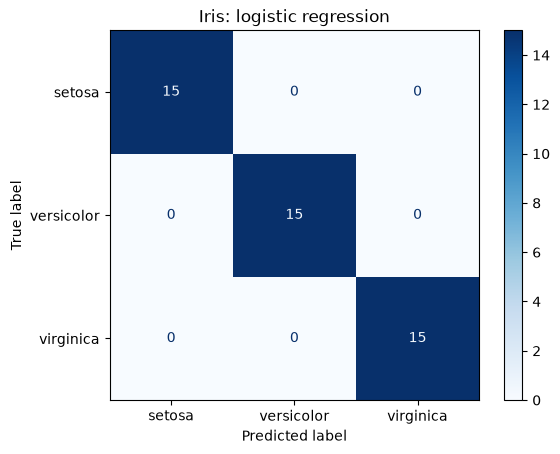

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(yi_test, lr.predict(Xi_test), cmap="Blues")
plt.title("Iris: logistic regression"); plt.show()

On this split logistic regression gets every test flower right. Iris is easy: setosa is never confused with anything, and when a model does slip (try other `random_state` values, or KNN in the exercises) it is always versicolor ↔ virginica, the two species whose petal sizes overlap.

### One-vs-rest, explicitly

`OneVsRestClassifier` wraps any binary model. Three "is it species k?" models, highest score wins.

In [6]:
from sklearn.multiclass import OneVsRestClassifier
ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000)).fit(Xi_train, yi_train)
print("number of binary models:", len(ovr.estimators_))
scores = pd.DataFrame(ovr.decision_function(Xi_test.iloc[:3]), columns=ovr.classes_).round(2)
scores["predicted"] = ovr.predict(Xi_test.iloc[:3])
scores

number of binary models: 3


,setosa,versicolor,virginica,predicted
0,-7.88,-1.68,2.91,virginica
1,-6.75,0.11,1.04,virginica
2,3.45,-1.84,-11.22,setosa


## 3. ShopWave: which catalogue?

The customer table from 01.9 with a three-way target: **none** (£0 next quarter), **standard** (£0–£500), **premium** (over £500).

> **About `train_test_split`.** We hold back 25% of customers and score the model only on those, because scoring a model on the rows it learned from is like marking your own homework. Module 04 explains this properly; for now, just know that `X_test` / `y_test` are "exam" customers the model never saw.

In [7]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd, numpy as np
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail
from sklearn.model_selection import train_test_split

xlsx = ensure_online_retail()
csv = xlsx.with_name("online_retail_2010_2011.csv")          # fast cache written by lesson 01.3
raw = pd.read_csv(csv, parse_dates=["InvoiceDate"]) if csv.exists() else pd.read_excel(xlsx, sheet_name="Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [8]:
# three-way target from next-quarter spend: none (£0), standard (£0-500), premium (>£500)
cust["catalogue"] = pd.cut(future_spend.reindex(cust.index).fillna(0), bins=[-1, 0, 500, np.inf],
                           labels=["none", "standard", "premium"])
print(cust["catalogue"].value_counts())
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    cust[features], cust["catalogue"], test_size=0.25, random_state=42, stratify=cust["catalogue"])

catalogue
none        1446
premium     1060
standard     811
Name: count, dtype: int64


In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
order = ["none", "standard", "premium"]
models = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN (k=15)":          make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
}
for name, m in models.items():
    m.fit(Xc_train, yc_train)
    print(f"=== {name}")
    print(classification_report(yc_test, m.predict(Xc_test), labels=order, digits=3))

=== logistic regression
              precision    recall  f1-score   support

        none      0.569     0.859     0.684       362
    standard      0.444     0.158     0.233       203
     premium      0.716     0.570     0.634       265

    accuracy                          0.595       830
   macro avg      0.576     0.529     0.517       830
weighted avg      0.585     0.595     0.558       830

=== KNN (k=15)
              precision    recall  f1-score   support

        none      0.571     0.801     0.667       362
    standard      0.372     0.143     0.206       203
     premium      0.656     0.604     0.629       265

    accuracy                          0.577       830
   macro avg      0.533     0.516     0.501       830
weighted avg      0.549     0.577     0.542       830



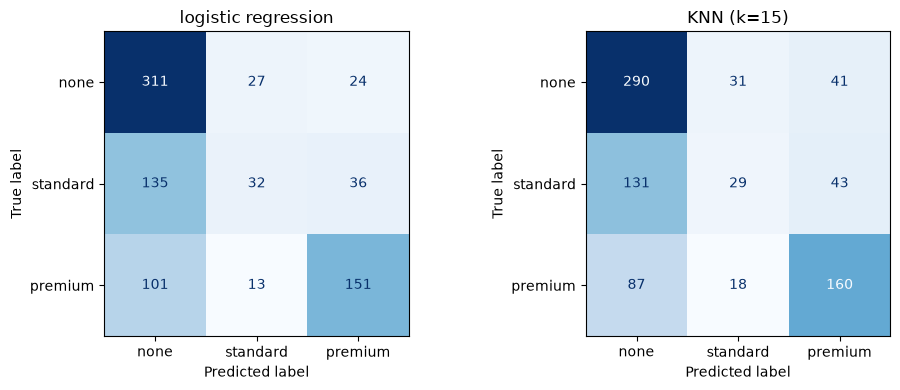

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(yc_test, m.predict(Xc_test), labels=order, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

Read the off-diagonal cells. The *standard* class is the problem: most standard customers are predicted *none*, and its recall is below 0.2. From past behaviour the model can tell big spenders from everyone else, but a customer who will spend a modest amount looks much like one who will not return at all. *Premium → none* is the next most common mistake; *none → premium* is rare. The macro F1 is dragged down by the standard class; the weighted F1 is propped up by the big *none* class. Exercise 4 shows what `class_weight="balanced"` does to this picture.

## Quiz answers

1. Every output is positive and they sum to 1, so they can be read as probabilities.
2. Down the "predicted = class 2" column: correct predictions of class 2 divided by everything predicted as class 2.
3. When a rare class has a much worse F1 than the big classes: macro weights it equally, weighted barely notices it.
4. Five, one per class.
5. Multi-**label**: a photo can carry several categories at once, so each category needs its own yes/no decision.

**Next:** [03.P Mini-project: Titanic survival, then ShopWave churn](../project/)